<a href="https://colab.research.google.com/github/huiyzhao/MSSP607/blob/main/WeeklyModules/Week09/huiyzhao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import userdata
import os
import subprocess

owner = "huiyzhao"
repository = "MSSP607"

clone_url = f'https://github.com/{owner}/{repository}.git'

import subprocess
subprocess.run(['git', 'clone', clone_url])

os.chdir(repository)
print(f"Changed directory to: {os.getcwd()}")

os.chdir("WeeklyModules/Week09")
print(os.getcwd())

Changed directory to: /content/MSSP607
/content/MSSP607/WeeklyModules/Week09


In [7]:
import requests
import bs4

category = "Cats"
url = "http://imgur.com/search?q=" + category

headers = {"User-Agent":"Mozilla/5.0"}
response = requests.get(url, headers=headers)

soup = bs4.BeautifulSoup(response.text, "html.parser")
image_tags = soup.select('img[src*="i.imgur.com"]')

print(len(image_tags))

59


In [8]:
cats = "imgur_cats"
os.makedirs(cats, exist_ok=True)

for number, image in enumerate(image_tags, start=1):
  image_url = image.get("src")

  if image_url.startswith("//"):
    image_url = "https:" + image_url

  image_response = requests.get(image_url, headers=headers)

  file_name = os.path.join(cats, f"cat_{number}.jpg")

  with open(file_name, "wb") as image_file:
    for chunk in image_response.iter_content(100000):
      image_file.write(chunk)

print("Downloaded", len(image_tags), "images to:", cats)

Downloaded 59 images to: imgur_cats


In [9]:
print(os.listdir("imgur_cats")[:5])
print(len(os.listdir("imgur_cats")))

['cat_28.jpg', 'cat_59.jpg', 'cat_4.jpg', 'cat_50.jpg', 'cat_8.jpg']
59


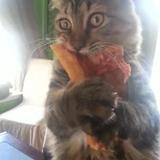

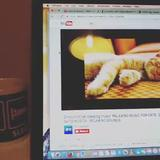

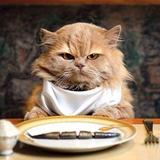

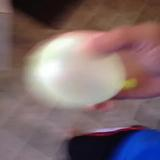

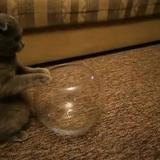

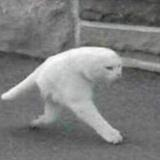

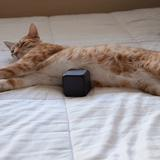

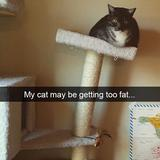

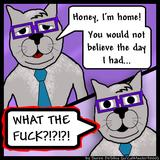

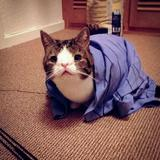

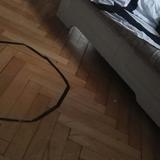

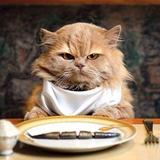

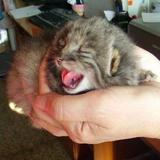

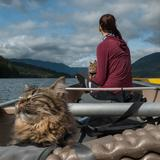

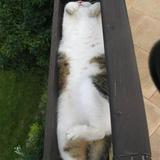

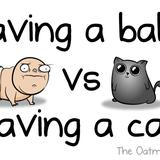

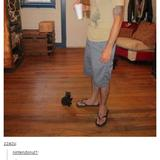

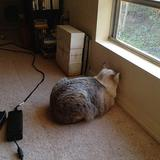

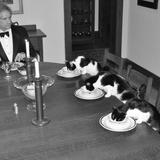

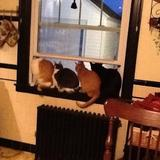

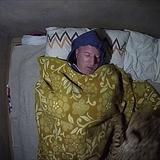

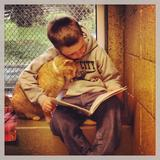

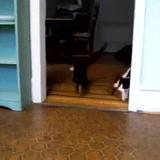

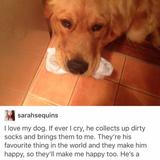

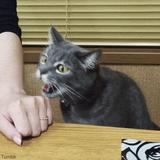

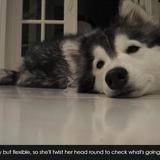

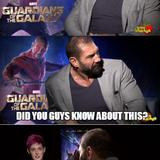

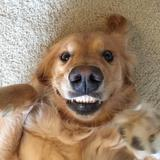

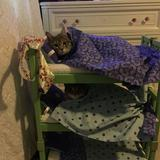

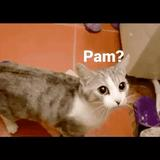

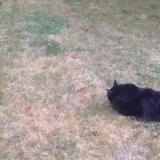

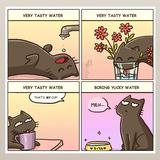

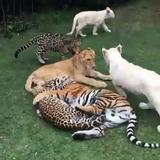

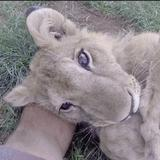

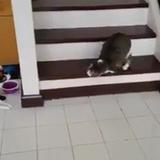

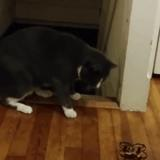

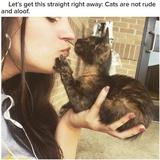

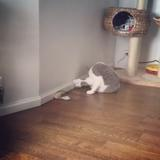

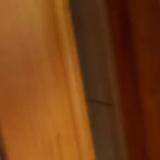

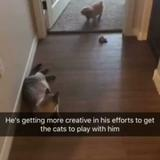

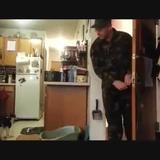

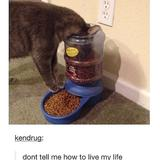

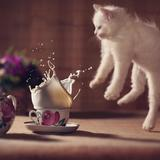

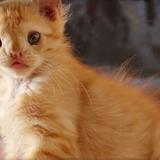

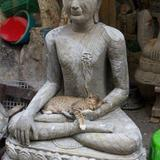

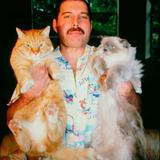

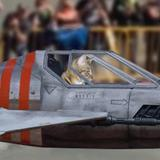

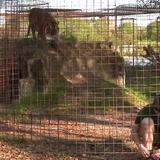

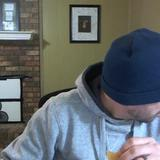

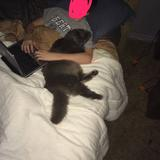

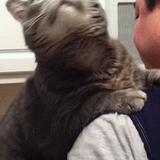

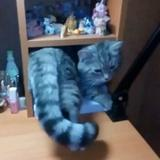

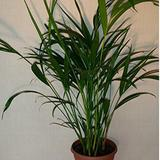

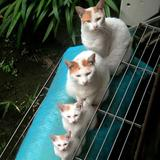

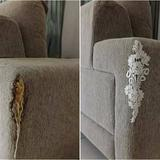

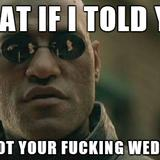

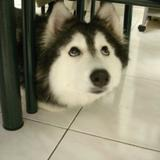

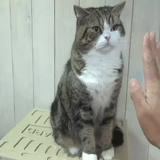

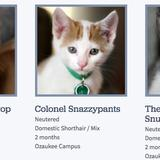

In [10]:
from IPython.display import Image, display
for number in range(1,len(image_tags)+1):
  display(Image(filename=f"imgur_cats/cat_{number}.jpg"))